<a href="https://colab.research.google.com/github/abhisheksvcs25-bms/Bio-Inspired-Systems/blob/YT-Hand-Gesture-Controller/1BM25CS406_PARTICLE_SWARM_OPTIMIZATION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Optimal Threshold: 83
Best Fitness: 5439.541512


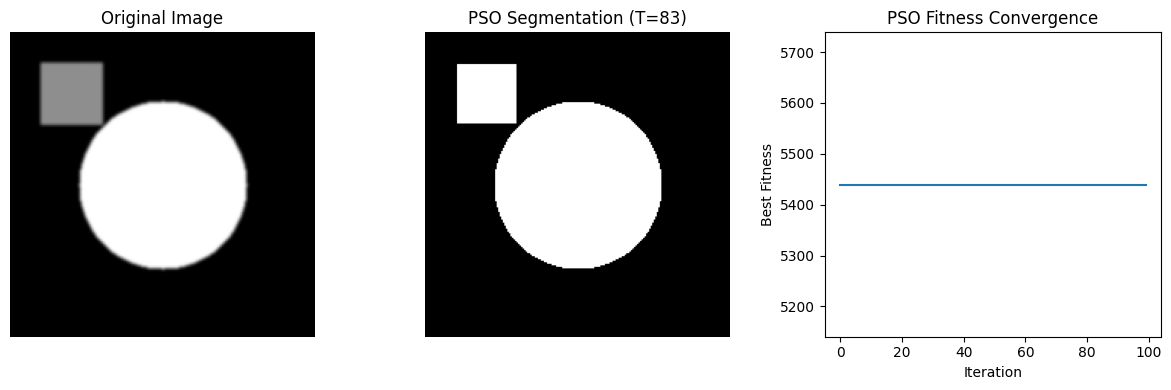

Segmented image saved as segmented_output.png


In [1]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

IMAGE_PATH = "input.jpg"

if os.path.exists(IMAGE_PATH):
    image = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
else:
    image = np.zeros((200, 200), dtype=np.uint8)
    cv2.circle(image, (100, 100), 55, 180, -1)
    cv2.rectangle(image, (20, 20), (60, 60), 100, -1)
    image = cv2.GaussianBlur(image, (5, 5), 0)

def fitness(threshold):
    hist = cv2.calcHist([image], [0], None, [256], [0, 256]).flatten()
    hist = hist / hist.sum()
    levels = np.arange(256)

    background = levels <= threshold
    foreground = levels > threshold

    w0 = hist[background].sum()
    w1 = hist[foreground].sum()

    if w0 == 0 or w1 == 0:
        return 0.0

    m0 = np.sum(levels[background] * hist[background]) / w0
    m1 = np.sum(levels[foreground] * hist[foreground]) / w1

    return w0 * w1 * (m0 - m1) ** 2

particles = np.random.uniform(0, 255, 20)
velocities = np.zeros(20)
pbest = particles.copy()
pbest_scores = np.array([fitness(p) for p in particles])

best_index = np.argmax(pbest_scores)
gbest = pbest[best_index]
gbest_score = pbest_scores[best_index]

w, c1, c2 = 0.7, 1.5, 1.5
history = []

for iteration in range(100):
    for i in range(len(particles)):
        r1, r2 = np.random.rand(), np.random.rand()

        velocities[i] = (
            w * velocities[i]
            + c1 * r1 * (pbest[i] - particles[i])
            + c2 * r2 * (gbest - particles[i])
        )

        particles[i] = np.clip(
            particles[i] + velocities[i], 0, 255
        )

        score = fitness(particles[i])

        if score > pbest_scores[i]:
            pbest[i] = particles[i]
            pbest_scores[i] = score

        if score > gbest_score:
            gbest = particles[i]
            gbest_score = score

    history.append(gbest_score)

threshold = int(round(gbest))
segmented = np.where(image > threshold, 255, 0).astype(np.uint8)

print("Optimal Threshold:", threshold)
print("Best Fitness:", round(gbest_score, 6))

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(segmented, cmap="gray")
plt.title(f"PSO Segmentation (T={threshold})")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.plot(history)
plt.title("PSO Fitness Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best Fitness")

plt.tight_layout()
plt.show()

cv2.imwrite("segmented_output.png", segmented)
print("Segmented image saved as segmented_output.png")
